<a href="https://colab.research.google.com/github/AleAsesino/mineriaDatosAnomaliasABCcarreteras/blob/main/preprocesamientoABCV1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Preprocesamiento**

In [11]:
install.packages(c("dbscan", "mclust"))
library(tidyverse)
library(lubridate)
library(dbscan)
library(mclust)

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Package 'mclust' version 6.1.4
Type 'citation("mclust")' for citing this R package in publications.


Attaching package: ‘mclust’


The following object is masked from ‘package:dplyr’:

    count


The following object is masked from ‘package:purrr’:

    map




In [12]:
# 1. Cargar dataset crudo
df_raw <- read_csv("data.csv", show_col_types = FALSE)

# Cota superior para eventos aún abiertos (vigentes en la última corrida)
ultima_consulta <- max(ymd_hms(df_raw$fecha_consulta, quiet = TRUE), na.rm = TRUE)

# 2. Limpieza base y filtro de conflicto social (estado LIKE 'e -%')
# - Se excluyen coordenadas (0, 0) inválidas.
# - Se mantienen marcas temporales en hora local de Bolivia (GMT-4) sin convertir a UTC.
df_conflictos <- df_raw %>%
  mutate(
    fecha_consulta = ymd_hms(fecha_consulta, quiet = TRUE),
    fecha_reporte  = ymd_hms(fecha_reporte, quiet = TRUE),
    fecha_fin      = ymd_hms(fecha_fin, quiet = TRUE),
    estado_norm    = str_to_lower(str_squish(coalesce(estado, "")))
  ) %>%
  filter(
    !is.na(fecha_reporte),
    str_starts(estado_norm, "e -"),
    !(latitud == 0 & longitud == 0),
    is.na(fecha_fin) | fecha_fin >= fecha_reporte
  ) %>%
  arrange(latitud, longitud, fecha_reporte)

# 3. Reconstrucción de episodios por coordenada (ventana > 24h separa episodios)
df_episodios <- df_conflictos %>%
  group_by(latitud, longitud) %>%
  mutate(
    fin_efectivo_prev = lag(cummax(as.numeric(coalesce(fecha_fin, ultima_consulta)))),
    fin_efectivo_prev = as_datetime(fin_efectivo_prev, tz = tz(fecha_reporte)),
    nuevo_episodio_flag = if_else(
      is.na(fin_efectivo_prev) |
        as.numeric(difftime(fecha_reporte, fin_efectivo_prev, units = "hours")) > 24,
      1L,
      0L
    ),
    id_episodio_coord = cumsum(nuevo_episodio_flag)
  ) %>%
  ungroup() %>%
  group_by(latitud, longitud, id_episodio_coord) %>%
  summarise(
    inicio_ep     = min(fecha_reporte, na.rm = TRUE),
    es_abierto_ep = any(is.na(fecha_fin)),
    fin_ep_cota   = if_else(any(is.na(fecha_fin)), ultima_consulta, max(fecha_fin, na.rm = TRUE)),
    duracion_ep_h = as.numeric(difftime(fin_ep_cota, inicio_ep, units = "hours")),
    n_filas_ep    = n(),
    .groups = "drop"
  ) %>%
  mutate(dia_inicio = as_date(inicio_ep))

# 4. Episodios iniciados por día
episodios_iniciados_diario <- df_episodios %>%
  group_by(dia = dia_inicio) %>%
  summarise(
    episodios_nuevos      = n(),
    duracion_prom_ep_h    = mean(duracion_ep_h, na.rm = TRUE),
    filas_conflicto_nuevo = sum(n_filas_ep, na.rm = TRUE),
    .groups = "drop"
  )

# 5. Episodios activos cada día (corte a las 12:00 hora local)
rango_dias <- seq.Date(
  from = min(as_date(df_conflictos$fecha_reporte), na.rm = TRUE),
  to   = max(as_date(ultima_consulta), na.rm = TRUE),
  by   = "day"
)

episodios_activos_diario <- tibble(dia = rango_dias) %>%
  rowwise() %>%
  mutate(
    corte_mediodia = as_datetime(paste0(dia, " 12:00:00"), tz = tz(ultima_consulta)),
    episodios_activos = sum(
      df_episodios$inicio_ep <= corte_mediodia & df_episodios$fin_ep_cota >= corte_mediodia,
      na.rm = TRUE
    )
  ) %>%
  ungroup() %>%
  select(dia, episodios_activos)

# Indicador de días con actividad registrada en la fuente
dias_con_actividad <- df_raw %>%
  mutate(dia_rep = as_date(ymd_hms(fecha_reporte, quiet = TRUE))) %>%
  distinct(dia_rep) %>%
  filter(!is.na(dia_rep)) %>%
  mutate(tiene_actividad_fuente = TRUE)

# 6. Consolidar dataset diario limpio
df_diario_limpio <- tibble(dia = rango_dias) %>%
  left_join(episodios_activos_diario, by = "dia") %>%
  left_join(episodios_iniciados_diario, by = "dia") %>%
  left_join(dias_con_actividad, by = c("dia" = "dia_rep")) %>%
  mutate(
    episodios_activos      = replace_na(episodios_activos, 0L),
    episodios_nuevos       = replace_na(episodios_nuevos, 0L),
    filas_conflicto_nuevo  = replace_na(filas_conflicto_nuevo, 0L),
    duracion_prom_ep_h     = replace_na(duracion_prom_ep_h, 0),
    tiene_actividad_fuente = replace_na(tiene_actividad_fuente, FALSE),
    log_episodios_activos  = log1p(episodios_activos),
    log_episodios_nuevos   = log1p(episodios_nuevos),
    log_duracion_prom_h    = log1p(duracion_prom_ep_h)
  )

write_csv(df_diario_limpio, "df_diario_limpio.csv")
cat("Guardado: df_diario_limpio.csv | Filas:", nrow(df_diario_limpio), "\n")
head(df_diario_limpio)

Guardado: df_diario_limpio.csv | Filas: 2292 


dia,episodios_activos,episodios_nuevos,duracion_prom_ep_h,filas_conflicto_nuevo,tiene_actividad_fuente,log_episodios_activos,log_episodios_nuevos,log_duracion_prom_h
<date>,<int>,<int>,<dbl>,<int>,<lgl>,<dbl>,<dbl>,<dbl>
2020-08-13,4,4,64.02389,4,TRUE,1.609438,1.609438,4.174755
2020-08-14,4,0,0.00000,0,TRUE,1.609438,0.000000,0.000000
2020-08-15,11,7,34.99337,7,TRUE,2.484907,2.079442,3.583335
2020-08-16,7,0,0.00000,0,TRUE,2.079442,0.000000,0.000000
2020-08-17,0,0,0.00000,0,TRUE,0.000000,0.000000,0.000000
2020-08-18,0,0,0.00000,0,TRUE,0.000000,0.000000,0.000000


In [13]:
# Cargar CSV limpio (útil si reinicias sesión y vas directo al modelado)
df_model <- read_csv("df_diario_limpio.csv", show_col_types = FALSE)

# Usamos transformaciones logarítmicas estandarizadas para reducir la asimetría de colas largas.
# Si prefieres evaluar días solo con actividad confirmada en la fuente, filtra:
# df_model <- df_model %>% filter(tiene_actividad_fuente)

X_scaled <- df_model %>%
  select(log_episodios_activos, log_duracion_prom_h) %>%
  scale() %>%
  as.matrix()

GMM óptimo -> Componentes (G): 6 | Modelo: EEV 
Anomalías detectadas (GMM P5): 115 


dia,episodios_activos,episodios_nuevos,duracion_prom_ep_h,cluster_gmm,log_dens_gmm
<date>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
2026-06-03,95,1,6.691667,3,-24.93770
2026-06-11,90,0,0.000000,6,-21.65029
2026-06-12,87,0,0.000000,6,-21.30590
2024-08-01,97,86,15.976638,3,-17.26982
2026-06-17,50,0,0.000000,6,-16.08878
2026-05-16,23,1,827.989167,5,-15.24874
2022-10-22,5,11,621.222045,5,-15.24160
2026-06-19,43,0,0.000000,6,-14.79043
2024-02-05,8,1,2.055833,6,-14.35548


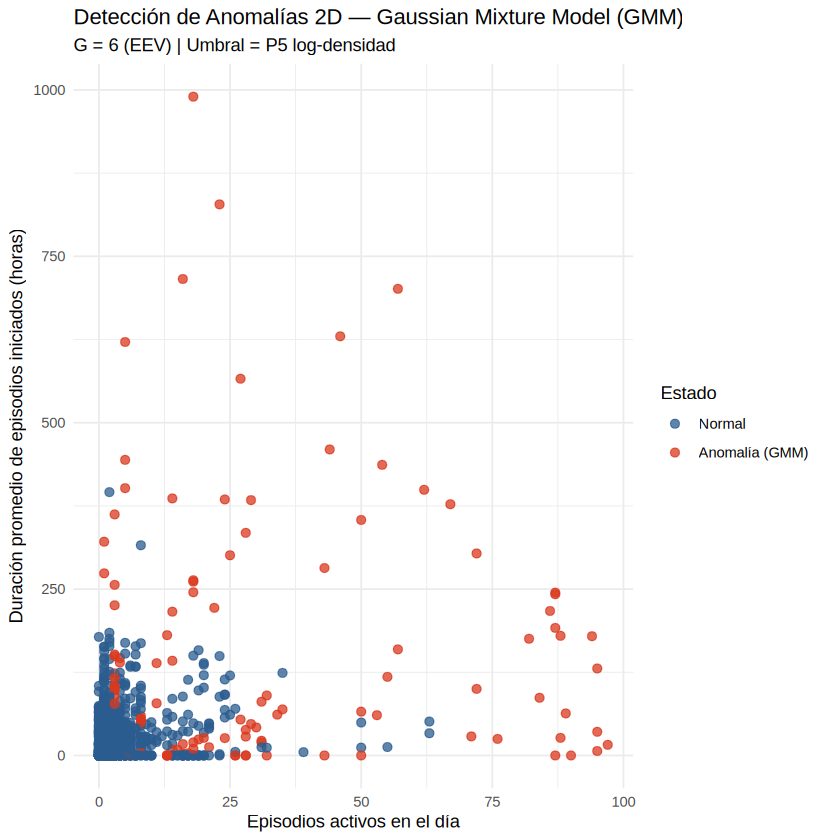

In [16]:
# 1. Ajustar GMM seleccionando número de componentes (1 a 6) y covarianza por BIC
gmm_fit <- Mclust(X_scaled, G = 1:6, verbose = FALSE)

# 2. Log-densidad bajo la mezcla Gaussiana:
# Usamos dens() pasando modelName y parameters de gmm_fit (o gmm_fit$density)
densidad_gmm <- dens(
  modelName  = gmm_fit$modelName,
  data       = X_scaled,
  parameters = gmm_fit$parameters,
  logarithm  = FALSE
)
log_dens_gmm <- log(pmax(densidad_gmm, .Machine$double.xmin))

# Umbral: 5% con menor densidad (percentil 5 de log-densidad)
umbral_gmm <- quantile(log_dens_gmm, probs = 0.05, na.rm = TRUE)

df_model <- df_model %>%
  mutate(
    cluster_gmm  = gmm_fit$classification,
    log_dens_gmm = log_dens_gmm,
    anomalia_gmm = log_dens_gmm < umbral_gmm
  )

cat("GMM óptimo -> Componentes (G):", gmm_fit$G, "| Modelo:", gmm_fit$modelName, "\n")
cat("Anomalías detectadas (GMM P5):", sum(df_model$anomalia_gmm), "\n")

df_model %>%
  filter(anomalia_gmm) %>%
  arrange(log_dens_gmm) %>%
  select(dia, episodios_activos, episodios_nuevos, duracion_prom_ep_h, cluster_gmm, log_dens_gmm) %>%
  head(10)

# Gráfico 2D - GMM
ggplot(df_model, aes(x = episodios_activos, y = duracion_prom_ep_h, color = anomalia_gmm)) +
  geom_point(alpha = 0.75, size = 2.2) +
  scale_color_manual(
    values = c("FALSE" = "#2b5c8f", "TRUE" = "#d9381e"),
    labels = c("Normal", "Anomalía (GMM)")
  ) +
  labs(
    title = "Detección de Anomalías 2D — Gaussian Mixture Model (GMM)",
    subtitle = paste0("G = ", gmm_fit$G, " (", gmm_fit$modelName, ") | Umbral = P5 log-densidad"),
    x = "Episodios activos en el día",
    y = "Duración promedio de episodios iniciados (horas)",
    color = "Estado"
  ) +
  theme_minimal()

Anomalías detectadas (LOF P95): 115 


dia,episodios_activos,episodios_nuevos,duracion_prom_ep_h,score_lof
<date>,<dbl>,<dbl>,<dbl>,<dbl>
2024-05-14,0,1,0.09666667,Inf
2026-06-17,50,0,0.00000000,4.441155
2026-06-11,90,0,0.00000000,4.355652
2026-06-12,87,0,0.00000000,4.278296
2026-06-19,43,0,0.00000000,3.885301
2024-10-29,23,1,2.08250000,3.689023
2025-12-04,0,1,178.14583333,3.593496
2022-11-04,16,1,2.87777778,3.475036
2022-11-08,17,1,3.33388889,3.183985


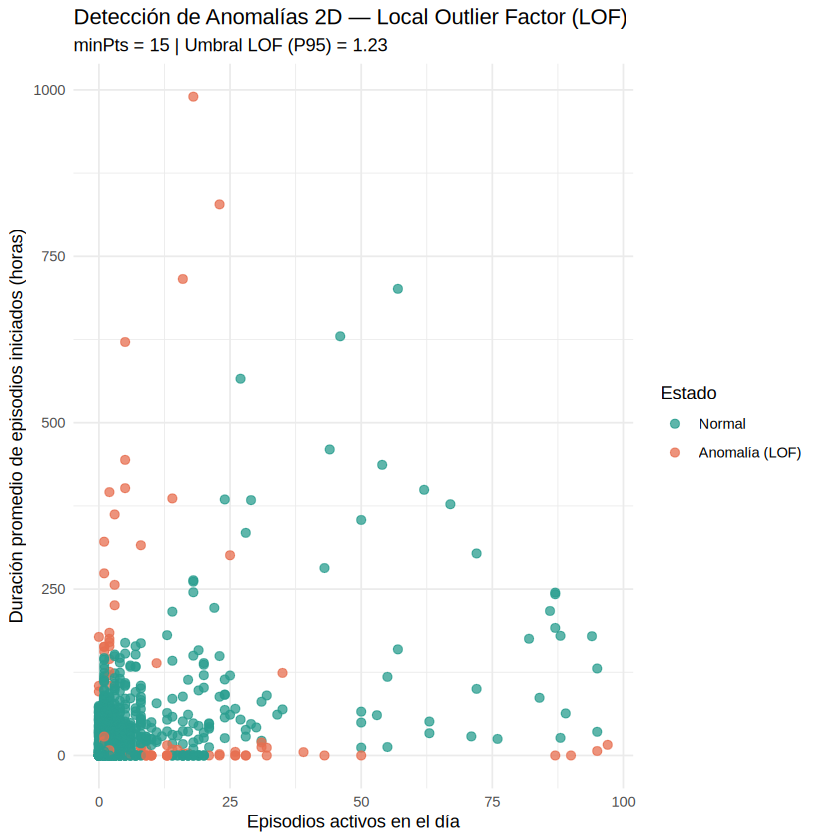

In [17]:
# 1. Calcular puntaje LOF (valores > 1 indican menor densidad local respecto a vecinos)
min_pts <- 15
scores_lof <- lof(X_scaled, minPts = min_pts)

# Umbral: percentil 95 de LOF
umbral_lof <- quantile(scores_lof, probs = 0.95, na.rm = TRUE)

df_model <- df_model %>%
  mutate(
    score_lof    = scores_lof,
    anomalia_lof = score_lof > umbral_lof
  )

cat("Anomalías detectadas (LOF P95):", sum(df_model$anomalia_lof), "\n")

df_model %>%
  filter(anomalia_lof) %>%
  arrange(desc(score_lof)) %>%
  select(dia, episodios_activos, episodios_nuevos, duracion_prom_ep_h, score_lof) %>%
  head(10)

# Gráfico 2D - LOF
ggplot(df_model, aes(x = episodios_activos, y = duracion_prom_ep_h, color = anomalia_lof)) +
  geom_point(alpha = 0.75, size = 2.2) +
  scale_color_manual(
    values = c("FALSE" = "#2a9d8f", "TRUE" = "#e76f51"),
    labels = c("Normal", "Anomalía (LOF)")
  ) +
  labs(
    title = "Detección de Anomalías 2D — Local Outlier Factor (LOF)",
    subtitle = paste0("minPts = ", min_pts, " | Umbral LOF (P95) = ", round(umbral_lof, 2)),
    x = "Episodios activos en el día",
    y = "Duración promedio de episodios iniciados (horas)",
    color = "Estado"
  ) +
  theme_minimal()

In [18]:
# Tabla cruzada de acuerdos y discrepancias
table(GMM = df_model$anomalia_gmm, LOF = df_model$anomalia_lof)

# Días marcados como anomalía por ambos métodos
df_model %>%
  filter(anomalia_gmm & anomalia_lof) %>%
  arrange(desc(episodios_activos)) %>%
  select(dia, episodios_activos, episodios_nuevos, duracion_prom_ep_h, log_dens_gmm, score_lof) %>%
  head(15)

       LOF
GMM     FALSE TRUE
  FALSE  2102   75
  TRUE     75   40

dia,episodios_activos,episodios_nuevos,duracion_prom_ep_h,log_dens_gmm,score_lof
<date>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
2024-08-01,97,86,15.976638,-17.269823,1.243798
2026-06-03,95,1,6.691667,-24.937696,1.326064
2026-06-11,90,0,0.000000,-21.650289,4.355652
2026-06-12,87,0,0.000000,-21.305903,4.278296
2026-06-17,50,0,0.000000,-16.088780,4.441155
2026-06-19,43,0,0.000000,-14.790434,3.885301
2021-11-13,32,0,0.000000,-10.655564,2.693190
2021-11-16,31,11,19.589773,-6.320764,1.263402
2021-11-14,28,0,0.000000,-8.173201,2.129580
